Epoch 1/10
1500/1500 [==============================] - 18s 11ms/step - loss: 0.4787 - accuracy: 0.8256 - val_loss: 0.3629 - val_accuracy: 0.8703
Epoch 2/10
1500/1500 [==============================] - 16s 11ms/step - loss: 0.3146 - accuracy: 0.8868 - val_loss: 0.3080 - val_accuracy: 0.8853
Epoch 3/10
1500/1500 [==============================] - 16s 10ms/step - loss: 0.2692 - accuracy: 0.9012 - val_loss: 0.2703 - val_accuracy: 0.9010
Epoch 4/10
1500/1500 [==============================] - 17s 11ms/step - loss: 0.2365 - accuracy: 0.9134 - val_loss: 0.2719 - val_accuracy: 0.8978
Epoch 5/10
1500/1500 [==============================] - 17s 11ms/step - loss: 0.2108 - accuracy: 0.9231 - val_loss: 0.2627 - val_accuracy: 0.9035
Epoch 6/10
1500/1500 [==============================] - 16s 10ms/step - loss: 0.1876 - accuracy: 0.9304 - val_loss: 0.2563 - val_accuracy: 0.9093
Epoch 7/10
1500/1500 [==============================] - 16s 11ms/step - loss: 0.1691 - accuracy: 0.9372 - val_loss: 0.2481 -

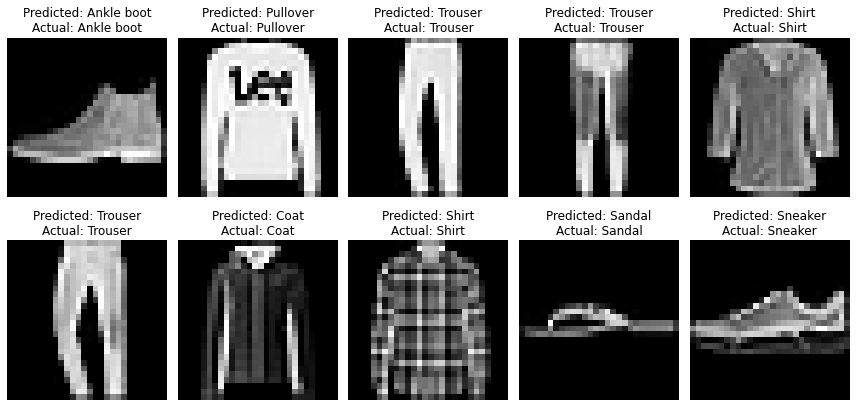

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten
import matplotlib.pyplot as plt

# Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Add channel dimension for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Build CNN
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=32
)

# Evaluate model
test_loss, test_acc = model.evaluate(x_test, y_test)

print(f"\nTest Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Show fashion images and predictions
predictions = model.predict(x_test[:10])

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    # Get predicted class
    predicted_class = tf.argmax(predictions[i]).numpy()

    plt.title(
        f"Predicted: {class_names[predicted_class]}\n"
        f"Actual: {class_names[y_test[i]]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()
